C:\Users\Hussin\AppData\Local\Temp\ipykernel_7484\1180039755.py:50: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




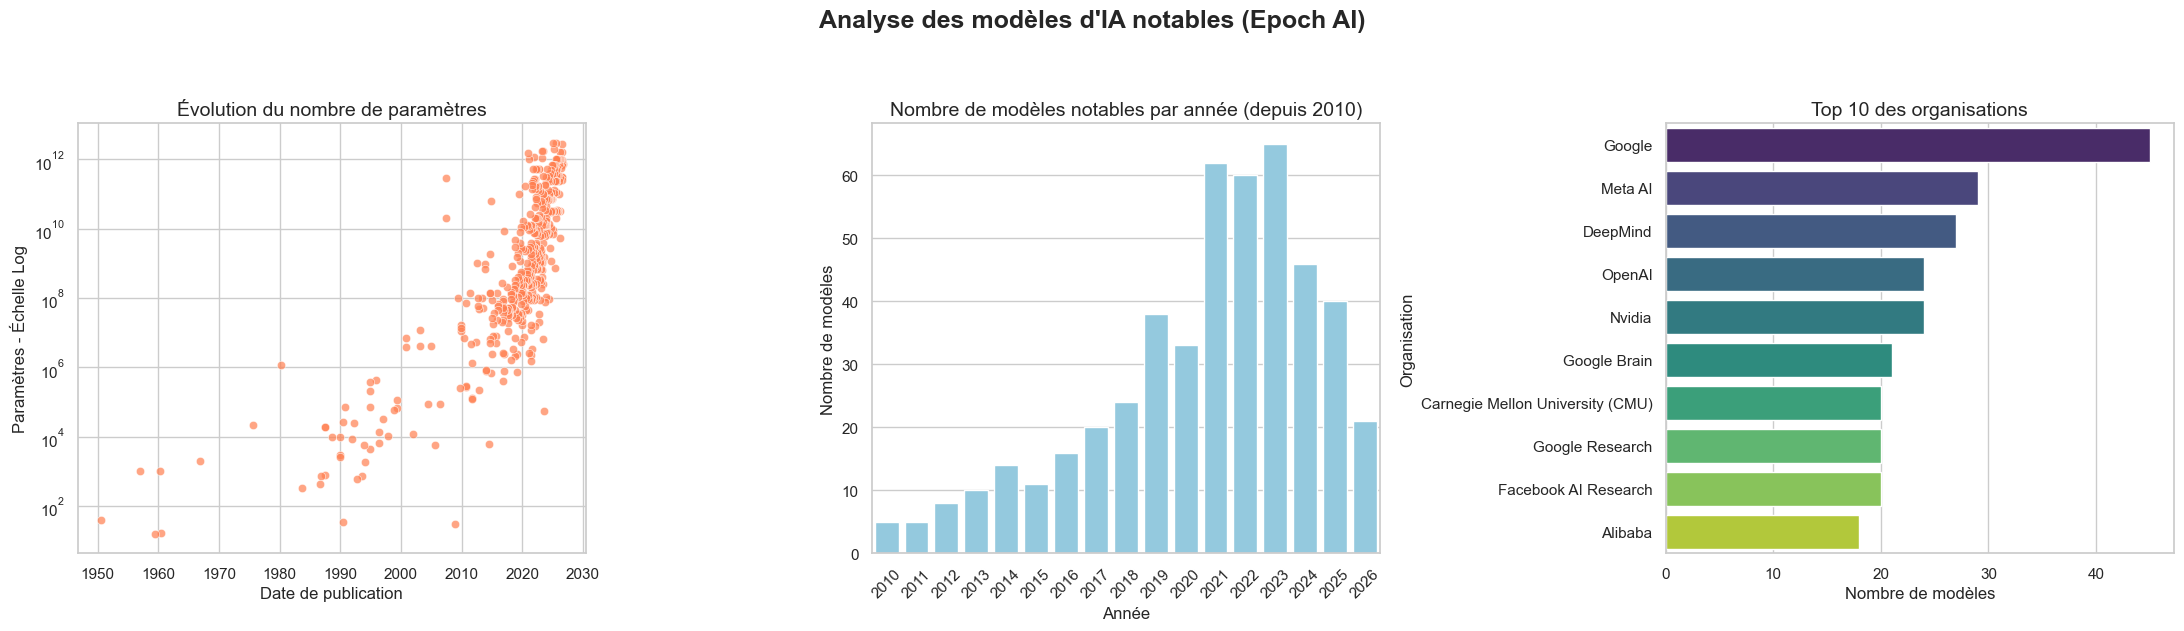

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuration initiale
sns.set_theme(style="whitegrid")
fichier_csv = "notable_ai_models_propre.csv"

df = pd.read_csv(fichier_csv)

# 2. Nettoyage et préparation des données
col_date = 'Publication date'
col_params = 'Parameters'
col_org = 'Organization'

# Conversion de la date en format datetime
df[col_date] = pd.to_datetime(df[col_date], errors='coerce')
df = df.dropna(subset=[col_date])
df['Year'] = df[col_date].dt.year

# 3. Création de la figure avec 3 sous-graphiques (1 ligne, 3 colonnes)
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
fig.suptitle("Analyse des modèles d'IA notables (Epoch AI)", fontsize=18, fontweight='bold', y=1.05)

# --- Graphique 1 : Évolution du nombre de paramètres ---
ax1 = axes[0]
if col_params in df.columns:
    df_params = df.dropna(subset=[col_params])
    sns.scatterplot(data=df_params, x=col_date, y=col_params, color='coral', alpha=0.7, ax=ax1)
    ax1.set_yscale('log')
    ax1.set_title('Évolution du nombre de paramètres', fontsize=14)
    ax1.set_xlabel('Date de publication')
    ax1.set_ylabel('Paramètres - Échelle Log')

# --- Graphique 2 : Nombre de modèles publiés par année ---
ax2 = axes[1]
models_per_year = df['Year'].value_counts().sort_index()
models_per_year = models_per_year[models_per_year.index >= 2010]
sns.barplot(x=models_per_year.index.astype(int), y=models_per_year.values, color='skyblue', ax=ax2)
ax2.set_title('Nombre de modèles notables par année (depuis 2010)', fontsize=14)
ax2.set_xlabel('Année')
ax2.set_ylabel('Nombre de modèles')
ax2.tick_params(axis='x', rotation=45)

# --- Graphique 3 : Top 10 des organisations ---
ax3 = axes[2]
if col_org in df.columns:
    orgs = df[col_org].dropna().str.split(',').explode().str.strip()
    top_orgs = orgs.value_counts().head(10)
    sns.barplot(y=top_orgs.index, x=top_orgs.values, palette='viridis', ax=ax3)
    ax3.set_title('Top 10 des organisations', fontsize=14)
    ax3.set_xlabel('Nombre de modèles')
    ax3.set_ylabel('Organisation')

# Ajustement de la mise en page et affichage
plt.tight_layout()
plt.show()

In [5]:
import pandas as pd
import plotly.graph_objects as go
import numpy as np

# 1. Chargement des données
df = pd.read_csv('notable_ai_models_propre.csv')
df_clean = df.dropna(subset=['Publication date', 'Training compute (FLOP)']).copy()

# Formatage de la date (ex: "Jul 9, 2025")
df_clean['Date_Formatted'] = pd.to_datetime(df_clean['Publication date']).dt.strftime('%b %-d, %Y')
df_clean['Publication date'] = pd.to_datetime(df_clean['Publication date'], errors='coerce')
df_clean = df_clean.dropna(subset=['Publication date'])

# 2. Fonction pour convertir les FLOP en PetaFLOP et formater textuellement
def format_petaflops(flop):
    if pd.isna(flop): return 'N/A'
    petaflop = flop / 1e15 # 1 petaFLOP = 10^15 FLOP
    
    if petaflop >= 1e12:
        return f"{petaflop/1e12:g} trillion"
    elif petaflop >= 1e9:
        return f"{petaflop/1e9:g} billion"
    elif petaflop >= 1e6:
        return f"{petaflop/1e6:g} million"
    elif petaflop >= 1e3:
        return f"{petaflop:,.0f}".replace(',', ' ')
    else:
        return f"{petaflop:g}"

df_clean['PetaFLOP_str'] = df_clean['Training compute (FLOP)'].apply(format_petaflops)

# 3. Empaqueter les données minimales pour le survol
custom_data = np.column_stack((
    df_clean['Model'],
    df_clean['Date_Formatted'],
    df_clean['PetaFLOP_str']
))

# Modèle de l'infobulle (Hover Template épuré)
hover_text = (
    "<b><span style='font-size:16px'>%{customdata[0]}</span></b><br>" +
    "%{customdata[1]}<br><br>" +
    "<span style='color:gray'>Training computation (petaFLOP)</span><br>" +
    "<b><span style='font-size:18px'>%{customdata[2]}</span></b>" +
    "<extra></extra>" 
)

# 4. Initialisation de la figure Plotly
fig = go.Figure()

# Ajout du nuage de points
fig.add_trace(go.Scatter(
    x=df_clean['Publication date'],
    y=df_clean['Training compute (FLOP)'],
    mode='markers',
    marker=dict(
        size=8,
        color='rgba(32, 178, 170, 0.6)', # Sarcelle transparent
        line=dict(width=1, color='rgba(30, 132, 127, 1)')
    ),
    customdata=custom_data,
    hovertemplate=hover_text,
    name='Models'
))

# 5. Ajout des textes statiques pour les modèles notables
models_to_annotate = [
    'Perceptron (1960)', 'Neocognitron', 'TD-Gammon', 'Neural LM',
    'RankNet', 'SB-LM', 'FLAN 137B', 'Swift', 'GPT-4.5', 'Grok 4'
]

for model_name in models_to_annotate:
    row = df_clean[df_clean['Model'] == model_name]
    if not row.empty:
        row = row.iloc[0]
        fig.add_annotation(
            x=row['Publication date'],
            y=np.log10(row['Training compute (FLOP)']),
            text=model_name,
            showarrow=False,
            yshift=12,
            font=dict(size=10, color="#008080")
        )

# 6. Ajout de la zone ombrée "Deep Learning Era"
fig.add_vrect(
    x0="2010-01-01", x1="2027-01-01",
    fillcolor="#E6F0F9", opacity=0.5,
    layer="below", line_width=0,
    annotation_text="Deep Learning Era", annotation_position="bottom right",
    annotation_font_size=14, annotation_font_color="#2c3e50"
)

# 7. Configuration de l'affichage
fig.update_layout(
    title=dict(text="<b>Notable AI models</b>", font=dict(size=24)),
    xaxis_title="Publication date",
    yaxis_title="Training compute (FLOP)",
    yaxis_type="log",
    yaxis_range=[1, 28],
    xaxis_range=["1948-01-01", "2027-01-01"],
    plot_bgcolor='white',
    hoverlabel=dict(
        bgcolor="white", 
        font_size=13, 
        font_family="Arial",
        bordercolor="#e0e0e0"
    ),
    width=1100,
    height=650
)

# Ajout d'une grille discrète
fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor='LightGray')
fig.update_yaxes(showgrid=True, gridwidth=1, gridcolor='LightGray')

# Affichage direct (sans sauvegarde)
fig.show()